In [2]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not on colab')

Mounted at /content/drive


# Movie Recommender System using MovieLens data (predict)
Author: Michael Fitiavana Randriamifidy

Created: 27 December 2025

Last Updated: 10 January 2026

In [3]:
import sys
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import re

In [4]:
DATA_SIZE_DICT= {
    0: "ml-latest-small",
    1: "ml-25m ",
    2: "ml-32m",
}
DATA_SIZE_STR = DATA_SIZE_DICT[2]

# Setting up

In [5]:
import importlib
sys.modules["imp"] = importlib
%load_ext autoreload
%reload_ext autoreload
%autoreload 2

## Setting up Notebooks

In [6]:
from typing import Optional, Callable, Dict, Any, List

def download_and_extract_movielens(
                            data_folders:List[str],
                            extracted_data_folder:str='./data',
                            data_size_str:str='ml-latest-small',
                            only_extract:bool=True
                            ):
    pattern = re.compile(rf"{data_size_str}\.zip$")
    for data_folder in data_folders:
        matches = [p for p in Path(data_folder).iterdir() if pattern.match(p.name)]
        if matches:
            print("Found zip file(s):", str(matches[-1]))
            break
    if not  matches:
        print(f"Downloading:{data_size_str}.zip from https://files.grouplens.org/datasets/movielens/{data_size_str}.zip")
        !curl -C - -O --output-dir "{data_folder}" "https://files.grouplens.org/datasets/movielens/{data_size_str}.zip"
    print(f"Extract to {extracted_data_folder}")
    !unzip -n "{data_folder}/{data_size_str}.zip" -d "{extracted_data_folder}"


    pattern = re.compile(rf"{data_size_str}\.zip.md5$")
    for data_folder in data_folders:
        matches = [p for p in Path(data_folder).iterdir() if pattern.match(str(p))]
        if matches:
            print("Found zip.md5 file(s):", str(matches[-1]))
            break
    if not  matches:
        print(f"Downloading:{data_size_str}.zip.md5 from https://files.grouplens.org/datasets/movielens/{data_size_str}.zip.md5")
        !curl -C - -O --output-dir "{data_folder}"  "https://files.grouplens.org/datasets/movielens/{data_size_str}.zip.md5"

def is_kaggle() -> bool:
    """
    Detect if the code is running on Kaggle.

    Returns:
        bool: True if running on Kaggle, False otherwise.
    """
    return "KAGGLE_URL_BASE" in os.environ


def is_colab() -> bool:
    """
    Detect if the code is running on Google Colab.

    Returns:
        bool: True if running on Google Colab, False otherwise.
    """
    try:
        import google.colab
        return True
    except ImportError:
        return False


def set_project(
    fun_todo_kaggle: Optional[Callable[..., Any]] = None,
    fun_todo_colab: Optional[Callable[..., Any]] = None,
    fun_todo_local: Optional[Callable[..., Any]] = None,
    kwargs_kaggle: Optional[Dict[str, Any]] = None,
    kwargs_colab: Optional[Dict[str, Any]] = None,
    kwargs_local: Optional[Dict[str, Any]] = None
) -> Optional[Any]:
    """
    Execute platform-specific setup functions based on the current environment.

    This function detects whether code is running on Kaggle, Google Colab, or locally,
    and executes the corresponding setup function with the provided keyword arguments.

    Args:
        fun_todo_kaggle: Optional function to execute on Kaggle.
        fun_todo_colab: Optional function to execute on Google Colab.
        fun_todo_local: Optional function to execute locally.
        kwargs_kaggle: Keyword arguments to pass to the Kaggle function.
        kwargs_colab: Keyword arguments to pass to the Colab function.
        kwargs_local: Keyword arguments to pass to the local function.

    Returns:
        The return value of the executed function, or None if no function is provided
        for the detected environment.
    """
    # Initialize kwargs dictionaries if None
    kwargs_kaggle = kwargs_kaggle or {}
    kwargs_colab = kwargs_colab or {}
    kwargs_local = kwargs_local or {}

    # Conditional commands
    if is_kaggle():
        print("Running on Kaggle")
        if fun_todo_kaggle is not None:
            return fun_todo_kaggle(**kwargs_kaggle)
    elif is_colab():
        print("Running on Google Colab")
        if fun_todo_colab is not None:
            return fun_todo_colab(**kwargs_colab)
    else:
        print("Running locally")
        if fun_todo_local is not None:
            return fun_todo_local(**kwargs_local)

    return None

def is_drive_mounted():
    return os.path.exists("/content/drive/MyDrive")


def fun_todo_kaggle(**kwargs):
    data_size_str = kwargs['data_size_str'] if "data_size_str" in kwargs else "latest-small"
    project_dir_abs = kwargs.get("project_dir_abs", Path.cwd())
    # os.chdir(project_dir_abs)
    REMOTE_PROJECT_PATH = Path(f"/kaggle/working/movie-recommender-system-{data_size_str}")
    PROJECT_PATH = Path("/kaggle/temp/")
    DATA_FOLDER = PROJECT_PATH / "download/data"
    EXTRACTED_DATA_FOLDER = Path("/kaggle/input/movielens-dataset/")
    PROJECT_PATH.mkdir(exist_ok=True, parents=True)
    EXTRACTED_DATA_FOLDER.mkdir(exist_ok=True, parents=True)
    REMOTE_PROJECT_PATH.mkdir(exist_ok=True, parents=True)
    DATA_FOLDER.mkdir(exist_ok=True, parents=True)
    !pwd
    !ls $REMOTE_PROJECT_PATH -R | head -20
    if project_dir_abs.as_posix() not in sys.path:
        sys.path.append(project_dir_abs.as_posix())
    print(sys.path)
    return REMOTE_PROJECT_PATH, PROJECT_PATH, DATA_FOLDER, EXTRACTED_DATA_FOLDER

def fun_todo_colab(**kwargs):
    if is_drive_mounted():
        print("Google Drive is already mounted")
    else:
        raise "Mount Drive"

    data_size_str = kwargs['data_size_str'] if "data_size_str" in kwargs else "latest-small"
    project_dir_abs = kwargs.get("project_dir_abs", Path.cwd())
    # os.chdir(project_dir_abs)
    REMOTE_PROJECT_PATH = Path(project_dir_abs) / f"working/movie-recommender-system-{data_size_str}"
    PROJECT_PATH =  Path(project_dir_abs) / f"temp/movie-recommender-system-{data_size_str}"
    DATA_FOLDER = Path("./downloads/data")
    EXTRACTED_DATA_FOLDER = Path("./data")
    PROJECT_PATH.mkdir(exist_ok=True, parents=True)
    EXTRACTED_DATA_FOLDER.mkdir(exist_ok=True, parents=True)
    REMOTE_PROJECT_PATH.mkdir(exist_ok=True, parents=True)
    DATA_FOLDER.mkdir(exist_ok=True, parents=True)
    !pwd
    !ls $REMOTE_PROJECT_PATH -R | head -20

    if project_dir_abs.as_posix() not in sys.path:
        sys.path.append(project_dir_abs.as_posix())
    print(sys.path)
    download_and_extract_movielens(
        [DATA_FOLDER, project_dir_abs / DATA_FOLDER],
        EXTRACTED_DATA_FOLDER,
        data_size_str = DATA_SIZE_STR)
    return REMOTE_PROJECT_PATH, PROJECT_PATH, DATA_FOLDER, EXTRACTED_DATA_FOLDER

def fun_todo_local(**kwargs):
    data_size_str = kwargs.get('data_size_str', 'latest-small')
    project_dir_abs = kwargs.get("project_dir_abs", Path.cwd())
    os.chdir(project_dir_abs)
    REMOTE_PROJECT_PATH = Path(project_dir_abs) / f"working/movie-recommender-system-{data_size_str}"
    PROJECT_PATH =  Path(project_dir_abs) / f"temp/movie-recommender-system-{data_size_str}"
    DATA_FOLDER = Path("./downloads/data")
    EXTRACTED_DATA_FOLDER = Path("./data")
    PROJECT_PATH.mkdir(exist_ok=True, parents=True)
    EXTRACTED_DATA_FOLDER.mkdir(exist_ok=True, parents=True)
    REMOTE_PROJECT_PATH.mkdir(exist_ok=True, parents=True)
    DATA_FOLDER.mkdir(exist_ok=True, parents=True)
    !pwd
    !ls $REMOTE_PROJECT_PATH -R | head -20
    if project_dir_abs.as_posix() not in sys.path:
        sys.path.append(project_dir_abs.as_posix())
    print(sys.path)

    download_and_extract_movielens(
        [DATA_FOLDER, project_dir_abs / DATA_FOLDER],
        EXTRACTED_DATA_FOLDER,
        data_size_str = DATA_SIZE_STR)
    return REMOTE_PROJECT_PATH, PROJECT_PATH, DATA_FOLDER, EXTRACTED_DATA_FOLDER


In [7]:
if Path.cwd().name == "notebooks":
    PROJECT_DIR_ABS = Path.cwd().parent
else:
    PROJECT_DIR_ABS = Path.cwd()
print(f"MovieLens data:{DATA_SIZE_STR}")
kwargs = {"data_size_str":DATA_SIZE_STR}
kwargs_kaggle = {**kwargs, **{'project_dir_abs':Path(f"/kaggle/input/movie-recommender-system-{DATA_SIZE_STR}")}}
kwargs_colab = {**kwargs, **{'project_dir_abs':Path(f"/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system")}}
kwargs_local = {**kwargs, **{'project_dir_abs':PROJECT_DIR_ABS}}
(
    REMOTE_PROJECT_PATH,
    PROJECT_PATH,
    DATA_FOLDER,
    EXTRACTED_DATA_FOLDER
    ) = set_project(fun_todo_kaggle,
                    fun_todo_colab,
                    fun_todo_local,
                    kwargs_kaggle=kwargs_kaggle,
                    kwargs_colab=kwargs_colab,
                    kwargs_local=kwargs_local)

ratings_path = EXTRACTED_DATA_FOLDER / DATA_SIZE_STR / "ratings.csv"
movies_path = EXTRACTED_DATA_FOLDER / DATA_SIZE_STR / "movies.csv"
PLOT_FOLDER = PROJECT_PATH / "plots"
MODEL_FOLDER = PROJECT_PATH / "models"
REMOTE_MODEL_FOLDER = REMOTE_PROJECT_PATH / "models"

MovieLens data:ml-32m
Running on Google Colab
Google Drive is already mounted
/content
/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/working/movie-recommender-system-ml-32m:
models

/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/working/movie-recommender-system-ml-32m/models:
with_embeddings
with_features

/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/working/movie-recommender-system-ml-32m/models/with_embeddings:
ml-32m-als-K02-best_nepochs14-maxiter50-lambda1-tau0.1-with_embeddings-latest.joblib
ml-32m-als-K02-best_nepochs21-maxiter50-lambda1-tau10-with_embeddings-latest.joblib
ml-32m-als-K02-best_nepochs23-maxiter50-lambda1-tau1-with_embeddings-latest.joblib
ml-32m-als-K04-best_nepochs15-maxiter50-lambda1-tau10-with_embeddings-latest.joblib
ml-32m-als-K04-best_nepochs22-maxiter50-lambda1-tau0.1-with_embeddings-latest.joblib
ml-32m-als-K04-best_nepochs23-maxiter50-lambda1-tau1-with_embeddings-latest.joblib
ml-32m-als-K08-best_nepochs12-m

## Import

In [ ]:
from recommender.utils.helpers import (
    set_project
    )
from recommender.plots.plotting import (
    plot_als_curves_multiple_models
)
from recommender.data.csr import (
    get_nrows_csr,
)
from recommender.models.model_io import (
    load_models_filtered
)
from recommender.data.ratings import (
    find_movie_id_by_title,
    get_idx_from_id,
    get_movie_info_from_id,
    get_movie_title_from_id,
    load_data_movie_feature_csr,
    load_movie_id_idx_mapping,
    load_ratings_and_features_data_csr,
)
from recommender.models.predict import (
    get_save_top_recommended
)

# Load movie datasets

In [9]:
(
    user_id_to_idx, user_idx_to_id, movie_id_to_idx, movie_idx_to_id,
    feature_idx_to_id, feature_id_to_idx,
    ratings_by_user_csr, ratings_by_movie_csr,
    features_by_movie_csr, movies_by_feature_csr, movies_title
)= load_ratings_and_features_data_csr(ratings_path, movies_path)
assert get_nrows_csr(ratings_by_user_csr) == get_nrows_csr(ratings_by_user_csr)

Loading ratings:   0%|          | 0/32000204 [00:00<?, ? lines/s]

Loading features:   0%|          | 0/87585 [00:00<?, ? lines/s]

In [10]:
(
    data_movie_id_to_idx,
    data_movie_idx_to_id,
    data_feature_id_to_idx,
    data_feature_idx_to_id,
    data_movies_title,
    movies_by_feature_csr,
    features_by_movie_csr,
    ) = load_data_movie_feature_csr(movies_path)

movie_id_to_idx, movie_idx_to_id = load_movie_id_idx_mapping(ratings_path)

Loading movies'feature:   0%|          | 0/87585 [00:00<?, ? movie/s]

Loading rated movie Id:   0%|          | 0/32000204 [00:00<?, ? ratings/s]

# Set User Ratings

## Search Movie by tittle

In [11]:
title = "Spider-Man"
title = "Captain America: The Winter Soldier"
title = "First Blood"
ids, titles = find_movie_id_by_title(title, movies_title, movie_idx_to_id, movie_id_to_idx)
results = get_movie_info_from_id(
    ids,
    movie_id_to_idx,
    feature_idx_to_id,
    movies_title,
    features_by_movie_csr
    )
display(pd.DataFrame(results))


,id,title,features
0,2402,Rambo: First Blood Part II (1985),"[Mystery, Thriller]"
1,2403,First Blood (Rambo: First Blood) (1982),[Comedy]
2,226476,Happy Tree Friends: Volume 1: First Blood (2002),"[Comedy, Romance]"


## Set ratings

In [12]:
# Toy Story
# dummy_ids = [120474]

# John Wick
# dummy_ids = [115149]

# Spider-Man (2002)
# dummy_ids = [5349]

# Captain America: The Winter Soldier (2014)
dummy_ids = [110102]

# Rambo: First Blood Part II (1985)
dummy_ids = [2402]

rated_movie_info = get_movie_info_from_id(
    dummy_ids, movie_id_to_idx, feature_idx_to_id,
    movies_title, features_by_movie_csr)

dummy_idx = get_idx_from_id(dummy_ids, movie_id_to_idx)
dummy_ratings = [5] * len(dummy_idx)
dummy_ratings_by_user = [[(idx, ratings) for idx, ratings in zip(dummy_idx, dummy_ratings)],]

rated_movie_title = get_movie_title_from_id(dummy_ids, movie_id_to_idx, movies_title)[-1]


print("Recommendation given the user rating")
df_user_ratings = pd.DataFrame(rated_movie_info)
df_user_ratings['rating'] = dummy_ratings
display(df_user_ratings)

Recommendation given the user rating


,id,title,features,rating
0,2402,Rambo: First Blood Part II (1985),"[Mystery, Thriller]",5


# Recommendation

## Model trained with Embeddings

### Load Model

In [48]:
K_list = [16]
vector_penality= 10
mode_dict = {
    0: "bias_only",
    1: "with_embeddings",
    2: "with_features"
}
mode = mode_dict[1]
models_folder =  Path(REMOTE_MODEL_FOLDER) / mode
pattern = r"(=?best_nepochs).*latest.joblib$"
models =  load_models_filtered(models_folder, K_list= K_list,vector_penality_list = [vector_penality],  pattern=pattern)

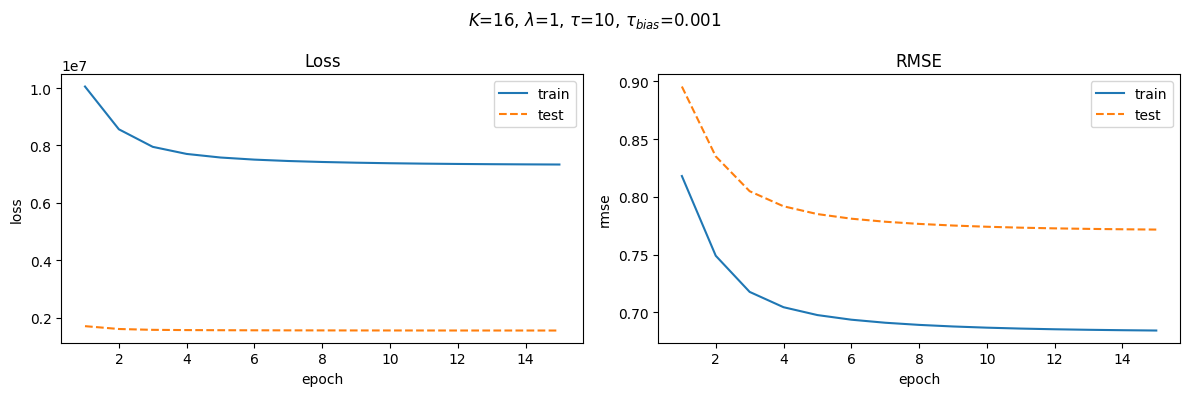

In [49]:
plot_als_curves_multiple_models(models)

In [50]:
fitted_model = models[-1]

### Predict

In [51]:
bias_factors =  [1.0, 1e-2, 1e-3]
max_iter = 50
ntop = 20
at_least_nratings=None

folder_save_path = Path(PROJECT_PATH) / 'predictions' / rated_movie_title
dfs = get_save_top_recommended(
    fitted_model,
    dummy_ratings_by_user,
    movie_idx_to_id,
    movie_id_to_idx,
    feature_idx_to_id,
    movies_title,
    features_by_movie_csr,
    ntop=ntop,
    max_iter=max_iter,
    atleast_nratings=at_least_nratings,
    bias_factors=bias_factors,
    save_to_latex= True,
    folder_save_path=folder_save_path,
)


  0%|          | 0/50 [00:00<?, ?it/s]

Model training Info with_embeddings, K=16, precision=1, bias_penality=0.001, vector_penality=10bias_factor=1.0
Movies recommended to user rating the movie:
- Rambo: First Blood Part II (1985): ['Mystery', 'Thriller'] (rating: 5)


,id,title,features
0,215541,Hello & Goodbye (2018),"[Comedy, Drama]"
1,225435,Wesley (2009),[Documentary]
2,216789,Destination: Pluto Beyond the Flyby (2016),"[Sci-Fi, Thriller]"
3,240054,SpongeBob SquarePants: Tide and Seek,"[Comedy, Drama]"
4,270306,WWE: The Triumph and Tragedy of World Class Ch...,"[Comedy, Drama, Romance]"
5,240070,SpongeBob SquarePants: Heroes of Bikini Bottom...,"[Crime, Drama]"
6,274047,The Sound of Violet (2022),[Drama]
7,225425,Pilgrim's Progress - Journey To Heaven (2008),[Documentary]
8,225437,Crazy Bible (2018),[Documentary]
9,151989,The Thorn (1971),[Drama]


  0%|          | 0/50 [00:00<?, ?it/s]

Model training Info with_embeddings, K=16, precision=1, bias_penality=0.001, vector_penality=10bias_factor=0.01
Movies recommended to user rating the movie:
- Rambo: First Blood Part II (1985): ['Mystery', 'Thriller'] (rating: 5)


,id,title,features
0,215541,Hello & Goodbye (2018),"[Comedy, Drama]"
1,225435,Wesley (2009),[Documentary]
2,216789,Destination: Pluto Beyond the Flyby (2016),"[Sci-Fi, Thriller]"
3,240054,SpongeBob SquarePants: Tide and Seek,"[Comedy, Drama]"
4,270306,WWE: The Triumph and Tragedy of World Class Ch...,"[Comedy, Drama, Romance]"
5,240070,SpongeBob SquarePants: Heroes of Bikini Bottom...,"[Crime, Drama]"
6,274047,The Sound of Violet (2022),[Drama]
7,225425,Pilgrim's Progress - Journey To Heaven (2008),[Documentary]
8,225437,Crazy Bible (2018),[Documentary]
9,151989,The Thorn (1971),[Drama]


  0%|          | 0/50 [00:00<?, ?it/s]

Model training Info with_embeddings, K=16, precision=1, bias_penality=0.001, vector_penality=10bias_factor=0.001
Movies recommended to user rating the movie:
- Rambo: First Blood Part II (1985): ['Mystery', 'Thriller'] (rating: 5)


,id,title,features
0,2402,Rambo: First Blood Part II (1985),"[Mystery, Thriller]"
1,2411,Rocky IV (1985),[Horror]
2,2403,First Blood (Rambo: First Blood) (1982),[Comedy]
3,2410,Rocky III (1982),"[Action, Drama, Mystery]"
4,3527,Predator (1987),"[Action, Crime]"
5,589,Terminator 2: Judgment Day (1991),[Drama]
6,2409,Rocky II (1979),"[Comedy, Drama]"
7,1954,Rocky (1976),"[Action, Crime, Drama]"
8,2404,Rambo III (1988),"[Drama, Romance]"
9,2985,RoboCop (1987),[Drama]


prediction saved with the name predict_with_embeddings-bias_factor=1.0.tex
prediction saved with the name predict_with_embeddings-bias_factor=0.01.tex
prediction saved with the name predict_with_embeddings-bias_factor=0.001.tex


### Predict After Filter out movies Less than 100 ratings

In [52]:
dummy_idx = get_idx_from_id(dummy_ids, movie_id_to_idx)
dummy_ratings_by_user = [[(idx, 5) for idx in dummy_idx],]

bias_factors =  [1.0, 1e-2, 1e-3]
max_iter = 50
ntop = 20
atleast_nratings=100

folder_save_path = Path(PROJECT_PATH) / 'predictions' / rated_movie_title
dfs = get_save_top_recommended(
    fitted_model,
    dummy_ratings_by_user,
    movie_idx_to_id,
    movie_id_to_idx,
    feature_idx_to_id,
    movies_title,
    features_by_movie_csr,
    ntop=ntop,
    max_iter=max_iter,
    atleast_nratings=atleast_nratings,
    bias_factors=bias_factors,
    save_to_latex= True,
    folder_save_path=folder_save_path,
)


  0%|          | 0/50 [00:00<?, ?it/s]

Model training Info with_embeddings, K=16, precision=1, bias_penality=0.001, vector_penality=10bias_factor=1.0
Movies recommended to user rating the movie:
- Rambo: First Blood Part II (1985): ['Mystery', 'Thriller'] (rating: 5)


,id,title,features
0,171011,Planet Earth II (2016),"[Action, Drama, Thriller]"
1,159817,Planet Earth (2006),"[Comedy, Drama]"
2,174703,I Am So Proud of You (2008),[Comedy]
3,220528,Twelve Angry Men (1954),"[Action, Comedy, Crime]"
4,170705,Band of Brothers (2001),"[Film-Noir, Horror]"
5,179135,Blue Planet II (2017),"[Drama, War]"
6,182723,Cosmos: A Spacetime Odissey,[Drama]
7,171495,Cosmos,[Drama]
8,318,"Shawshank Redemption, The (1994)","[Action, Romance, Western]"
9,261955,The Rescue (2021),"[Comedy, Romance]"


  0%|          | 0/50 [00:00<?, ?it/s]

Model training Info with_embeddings, K=16, precision=1, bias_penality=0.001, vector_penality=10bias_factor=0.01
Movies recommended to user rating the movie:
- Rambo: First Blood Part II (1985): ['Mystery', 'Thriller'] (rating: 5)


,id,title,features
0,589,Terminator 2: Judgment Day (1991),[Drama]
1,170705,Band of Brothers (2001),"[Film-Noir, Horror]"
2,1036,Die Hard (1988),"[Drama, Romance]"
3,1954,Rocky (1976),"[Action, Crime, Drama]"
4,1240,"Terminator, The (1984)","[Adventure, Children, Drama]"
5,110,Braveheart (1995),[Action]
6,171011,Planet Earth II (2016),"[Action, Drama, Thriller]"
7,159817,Planet Earth (2006),"[Comedy, Drama]"
8,2028,Saving Private Ryan (1998),"[Drama, Romance]"
9,1201,"Good, the Bad and the Ugly, The (Buono, il bru...","[Children, Drama, Fantasy]"


  0%|          | 0/50 [00:00<?, ?it/s]

Model training Info with_embeddings, K=16, precision=1, bias_penality=0.001, vector_penality=10bias_factor=0.001
Movies recommended to user rating the movie:
- Rambo: First Blood Part II (1985): ['Mystery', 'Thriller'] (rating: 5)


,id,title,features
0,2402,Rambo: First Blood Part II (1985),"[Mystery, Thriller]"
1,2411,Rocky IV (1985),[Horror]
2,2403,First Blood (Rambo: First Blood) (1982),[Comedy]
3,2410,Rocky III (1982),"[Action, Drama, Mystery]"
4,3527,Predator (1987),"[Action, Crime]"
5,589,Terminator 2: Judgment Day (1991),[Drama]
6,2409,Rocky II (1979),"[Comedy, Drama]"
7,1954,Rocky (1976),"[Action, Crime, Drama]"
8,2404,Rambo III (1988),"[Drama, Romance]"
9,2985,RoboCop (1987),[Drama]


prediction saved with the name predict_with_embeddings-bias_factor=1.0filtered_atleast100_ratings.tex
prediction saved with the name predict_with_embeddings-bias_factor=0.01filtered_atleast100_ratings.tex
prediction saved with the name predict_with_embeddings-bias_factor=0.001filtered_atleast100_ratings.tex


## Model trained with Features

### Load Model

In [53]:
K_list = [16]
vector_penality= 1
mode_dict = {
    0: "bias_only",
    1: "with_embeddings",
    2: "with_features"
}
mode = mode_dict[2]
models_folder =  Path(REMOTE_MODEL_FOLDER) / mode
pattern = r"(=?best_nepochs).*latest.joblib$"
models =  load_models_filtered(models_folder, K_list= K_list,vector_penality_list = [vector_penality],  pattern=pattern)

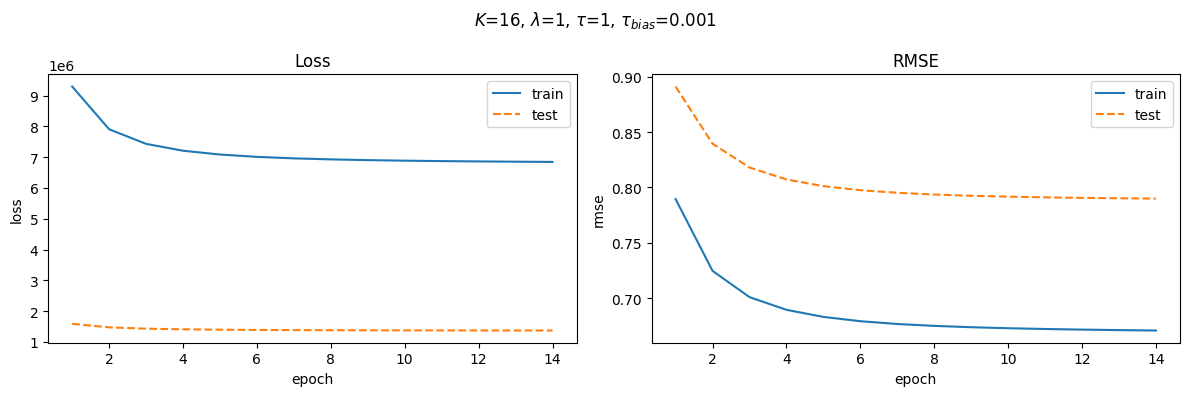

In [54]:
plot_als_curves_multiple_models(models)

In [55]:
fitted_model = models[-1]

### Predict

In [56]:
dummy_idx = get_idx_from_id(dummy_ids, movie_id_to_idx)
dummy_ratings_by_user = [[(idx, 5) for idx in dummy_idx],]

bias_factors =  [1.0, 1e-2, 1e-3]
max_iter = 50
ntop = 20
at_least_nratings=None

folder_save_path = Path(PROJECT_PATH) / 'predictions' / rated_movie_title
dfs = get_save_top_recommended(
    fitted_model,
    dummy_ratings_by_user,
    movie_idx_to_id,
    movie_id_to_idx,
    feature_idx_to_id,
    movies_title,
    features_by_movie_csr,
    ntop=ntop,
    max_iter=max_iter,
    atleast_nratings=at_least_nratings,
    bias_factors=bias_factors,
    save_to_latex= True,
    folder_save_path=folder_save_path,
)


  0%|          | 0/50 [00:00<?, ?it/s]

Model training Info with_features, K=16, precision=1, bias_penality=0.001, vector_penality=1bias_factor=1.0
Movies recommended to user rating the movie:
- Rambo: First Blood Part II (1985): ['Mystery', 'Thriller'] (rating: 5)


,id,title,features
0,216789,Destination: Pluto Beyond the Flyby (2016),"[Sci-Fi, Thriller]"
1,195549,The Monster of Phantom Lake (2006),"[Drama, Fantasy, Sci-Fi]"
2,256835,Joey and Ella (2021),[Documentary]
3,235787,A Dramatic Film (2019),[Action]
4,291981,Abducted by My Teacher: The Elizabeth Thomas S...,[Documentary]
5,224104,Stand Your Ground (2013),"[Horror, Sci-Fi]"
6,215541,Hello & Goodbye (2018),"[Comedy, Drama]"
7,253946,48 Below (2012),"[Drama, Romance]"
8,291264,Champions (2008),[(no genres listed)]
9,270306,WWE: The Triumph and Tragedy of World Class Ch...,"[Comedy, Drama, Romance]"


  0%|          | 0/50 [00:00<?, ?it/s]

Model training Info with_features, K=16, precision=1, bias_penality=0.001, vector_penality=1bias_factor=0.01
Movies recommended to user rating the movie:
- Rambo: First Blood Part II (1985): ['Mystery', 'Thriller'] (rating: 5)


,id,title,features
0,2411,Rocky IV (1985),[Horror]
1,2402,Rambo: First Blood Part II (1985),"[Mystery, Thriller]"
2,2410,Rocky III (1982),"[Action, Drama, Mystery]"
3,2404,Rambo III (1988),"[Drama, Romance]"
4,4614,Kickboxer (1989),"[Crime, Drama, Fantasy, Film-Noir, Mystery, Ro..."
5,3432,Death Wish 3 (1985),"[Action, Comedy, Crime]"
6,3431,Death Wish 2 (1982),[Drama]
7,6800,Cobra (1986),"[Comedy, Crime]"
8,2403,First Blood (Rambo: First Blood) (1982),[Comedy]
9,6664,Commando (1985),"[Crime, Thriller]"


  0%|          | 0/50 [00:00<?, ?it/s]

Model training Info with_features, K=16, precision=1, bias_penality=0.001, vector_penality=1bias_factor=0.001
Movies recommended to user rating the movie:
- Rambo: First Blood Part II (1985): ['Mystery', 'Thriller'] (rating: 5)


,id,title,features
0,30793,Charlie and the Chocolate Factory (2005),[Romance]
1,152503,Lockjaw: Rise of the Kulev Serpent (2008),"[Action, Adventure, Animation, Sci-Fi]"
2,209887,"My Love, My Bride (2014)","[Animation, Romance]"
3,263815,Tigger & Pooh and a Musical Too (2009),"[Comedy, Drama]"
4,342,Muriel's Wedding (1994),"[Comedy, Romance]"
5,280624,Os Trapalhões e o Rei do Futebol (1986),[Documentary]
6,69844,Harry Potter and the Half-Blood Prince (2009),"[Comedy, Drama, Mystery, Romance]"
7,283187,Étude 65 (1965),[Drama]
8,27706,Lemony Snicket's A Series of Unfortunate Event...,[Comedy]
9,8376,Napoleon Dynamite (2004),"[Drama, War]"


prediction saved with the name predict_with_features-bias_factor=1.0.tex
prediction saved with the name predict_with_features-bias_factor=0.01.tex
prediction saved with the name predict_with_features-bias_factor=0.001.tex


### Predict After Filter out movies Less than 100 ratings

In [57]:
dummy_idx = get_idx_from_id(dummy_ids, movie_id_to_idx)
dummy_ratings_by_user = [[(idx, 5) for idx in dummy_idx],]

bias_factors =  [1.0, 1e-2, 1e-3]
max_iter = 50
ntop = 20
atleast_nratings=100

folder_save_path = Path(PROJECT_PATH) / 'predictions' / rated_movie_title
dfs = get_save_top_recommended(
    fitted_model,
    dummy_ratings_by_user,
    movie_idx_to_id,
    movie_id_to_idx,
    feature_idx_to_id,
    movies_title,
    features_by_movie_csr,
    ntop=ntop,
    max_iter=max_iter,
    atleast_nratings=atleast_nratings,
    bias_factors=bias_factors,
    save_to_latex= True,
    folder_save_path=folder_save_path,
)


  0%|          | 0/50 [00:00<?, ?it/s]

Model training Info with_features, K=16, precision=1, bias_penality=0.001, vector_penality=1bias_factor=1.0
Movies recommended to user rating the movie:
- Rambo: First Blood Part II (1985): ['Mystery', 'Thriller'] (rating: 5)


,id,title,features
0,159817,Planet Earth (2006),"[Comedy, Drama]"
1,171011,Planet Earth II (2016),"[Action, Drama, Thriller]"
2,170705,Band of Brothers (2001),"[Film-Noir, Horror]"
3,220528,Twelve Angry Men (1954),"[Action, Comedy, Crime]"
4,179135,Blue Planet II (2017),"[Drama, War]"
5,93040,"Civil War, The (1990)","[Comedy, Documentary, Drama]"
6,318,"Shawshank Redemption, The (1994)","[Action, Romance, Western]"
7,171495,Cosmos,[Drama]
8,142115,The Blue Planet (2001),"[Action, Fantasy]"
9,173535,The Adventures of Sherlock Holmes and Doctor W...,"[Adventure, Comedy, Drama]"


  0%|          | 0/50 [00:00<?, ?it/s]

Model training Info with_features, K=16, precision=1, bias_penality=0.001, vector_penality=1bias_factor=0.01
Movies recommended to user rating the movie:
- Rambo: First Blood Part II (1985): ['Mystery', 'Thriller'] (rating: 5)


,id,title,features
0,2411,Rocky IV (1985),[Horror]
1,2402,Rambo: First Blood Part II (1985),"[Mystery, Thriller]"
2,2410,Rocky III (1982),"[Action, Drama, Mystery]"
3,2404,Rambo III (1988),"[Drama, Romance]"
4,4614,Kickboxer (1989),"[Crime, Drama, Fantasy, Film-Noir, Mystery, Ro..."
5,3432,Death Wish 3 (1985),"[Action, Comedy, Crime]"
6,3431,Death Wish 2 (1982),[Drama]
7,6800,Cobra (1986),"[Comedy, Crime]"
8,2403,First Blood (Rambo: First Blood) (1982),[Comedy]
9,6664,Commando (1985),"[Crime, Thriller]"


  0%|          | 0/50 [00:00<?, ?it/s]

Model training Info with_features, K=16, precision=1, bias_penality=0.001, vector_penality=1bias_factor=0.001
Movies recommended to user rating the movie:
- Rambo: First Blood Part II (1985): ['Mystery', 'Thriller'] (rating: 5)


,id,title,features
0,2411,Rocky IV (1985),[Horror]
1,2402,Rambo: First Blood Part II (1985),"[Mystery, Thriller]"
2,2404,Rambo III (1988),"[Drama, Romance]"
3,3432,Death Wish 3 (1985),"[Action, Comedy, Crime]"
4,2410,Rocky III (1982),"[Action, Drama, Mystery]"
5,3431,Death Wish 2 (1982),[Drama]
6,6800,Cobra (1986),"[Comedy, Crime]"
7,4614,Kickboxer (1989),"[Crime, Drama, Fantasy, Film-Noir, Mystery, Ro..."
8,6664,Commando (1985),"[Crime, Thriller]"
9,2403,First Blood (Rambo: First Blood) (1982),[Comedy]


prediction saved with the name predict_with_features-bias_factor=1.0filtered_atleast100_ratings.tex
prediction saved with the name predict_with_features-bias_factor=0.01filtered_atleast100_ratings.tex
prediction saved with the name predict_with_features-bias_factor=0.001filtered_atleast100_ratings.tex
